<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/QBM_AnomalyDetection_Stein2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBM for unsupervised anomaly detection (EDR): Stein et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Jonas Stein, Daniëlle Schumann, Magdalena Benkard, Thomas Holger, Wanja Sajko, Michael Kölle, Jonas Nüßlein, Leo Sünkel,
> Olivier Salomon and Claudia Linnhoff-Popien,
> "Exploring Unsupervised Anomaly Detection with Quantum Boltzmann Machines in Fraud Detection",
> Proceedings of ICAART 2024 (SCITEPRESS), DOI 10.5220/0012326100003636, arXiv:2306.04998v3 [quant-ph], January 2024.
> The authors' code is at https://github.com/jonas-stein/QBM-Anomaly-Detection (not used here; everything below is re-written from the paper).

**What the notebook does.** The paper (despite "Fraud Detection" in its title) trains a *semi-restricted quantum Boltzmann machine* (QBM) and a
*restricted Boltzmann machine* (RBM) on a synthetic, endpoint-detection-inspired point cloud, with no labels. A point is called anomalous when its
energy under the trained model exceeds the 95th percentile of the training energies. The notebook (1) generates the paper's kind of data
(`make_blobs`, 1007 points, 3 dimensions, 7 bits per dimension, 5 clusters + 7 anomalies), (2) implements both Boltzmann machines in plain NumPy with
a **simulated-annealing (SA) sampler**, which is exactly the sampler the paper used for its hyper-parameter search and for the "SA" column of its
Table 1, (3) re-draws the paper's hyper-parameter curves (Figs. 3-5) and Table 1, (4) compares with Isolation Forest and a one-class SVM on the
same points, and (5) adds an **exact** transverse-field QBM (Gibbs state computed in closed form and checked against a dense 5-qubit matrix exponential)
to show what an ideal sampler would give.

**What cannot be reproduced here.** The D-Wave 2000Q and Advantage 4.1 columns of Table 1 need a quantum annealer (the authors had about 3 hours of QPU time);
they are marked "cannot be checked". No credit-card data is used: the paper's experiment is on its own synthetic data and this notebook generates the same kind of data.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. No quantum SDK, GPU, IBM account or token is needed; only
NumPy, scikit-learn and matplotlib. `FAST_MODE = True` is a class demo (a few minutes); `FAST_MODE = False` uses the paper's budgets (about 1 hour on a laptop CPU).

**What you get at the end.** A table of the paper's numbers next to ours with a verdict per claim, the energy box plot of the paper's Fig. 6, and an exact-QBM study of the
transverse field.

## The paper in one page

**Problem.** Find rare malicious points in a large stream of endpoint-detection (EDR) data without labels. Classical clustering or auto-encoders often cannot separate malicious from benign anomalies.

**Decision.** For each point, compute its energy under a trained Boltzmann machine. Points with energy above the p-th percentile (p = 95) of the *training* energies are flagged as anomalies (Sec. 4.2). Low energy means high model probability, i.e. "normal".

**Models.** A *semi-restricted* QBM (Fig. 1b): visible layer v (21 bits), one hidden layer h, weights between v and h **and** lateral weights between visible units. The RBM baseline (Fig. 1a) has no lateral weights. Energy (paper Eq. 1 and 4), trained by the usual
Boltzmann-machine gradient `<s_i s_j>_data - <s_i s_j>_model` (Eqs. 2-3). The "quantum" ingredient is only the sampler: a quantum annealer (D-Wave 2000Q or Advantage 4.1) draws the model samples. For the hyper-parameter search the authors used classical simulated annealing instead (about 2 days of QPU time would have been needed).

**Data (Sec. 5.1).** 1007 synthetic 3-D points with integer coordinates in 0..127, generated with scikit-learn's `make_blobs`: 5 clusters + 7 anomalies. Each coordinate is written with 7 bits, so 21 visible units. 50/50 train/test split, results only on the test half (about 3 to 4 anomalies, below 1 %).

**Hyper-parameter search (Sec. 5.2).** Greedy: hidden units, then epochs, then batch size, 3 seeds. Optima: QBM 82 hidden, 7 epochs (F1 0.35, 0.375 at 14-16 epochs); RBM 157 hidden, 13 epochs (F1 0.33); batch size 10 for both.

**Claims (Table 1, final test with 5 seeds).**

| | RBM | SA (QBM, simulated annealing) | D-Wave 2000Q | D-Wave Advantage 4.1 |
|---|---|---|---|---|
| F1 | 0.33 | 0.35 | 0.14 | 0.21 |
| Recall | 1 | 1 | 0.67 | 0.67 |
| Precision | 0.20 | 0.21 | 0.08 | 0.13 |

Further claims: the QBM reaches its best F1 with fewer hidden units (82 vs 157) and about half the epochs of the RBM; the RBM's energy variance (Fig. 6) is lower than the QBM's; the quantum annealers are still outperformed by the classical approaches.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data generator | `make_blobs`, 1000 cluster points + 7 anomalies, ints 0..127, 5 clusters | same sizes; centres uniform in [25, 102]^3, cluster std 6, anomalies uniform in the cube but at least 30 away from every centre (`# CHOICE`) |
| Binary code | 7 bits per dimension, 21 visible units | plain binary, most significant bit first |
| Split | 50/50 train/test, anomalies kept in training | stratified on the anomaly flag so both halves contain anomalies |
| Seeds | 3 (search), 5 (final) | same; a seed changes the data, split and training |
| Architecture | semi-restricted BM: v-h and v-v weights, no h-h weights | same; RBM = same code with the v-v weights frozen at 0 |
| Sampler | D-Wave 2000Q / Advantage 4.1, or SA (D-Wave `neal`) | heat-bath simulated annealing written in NumPy (`# CHOICE`): beta ramps linearly 0.1 -> 1, hidden layer updated in one block, visible units sequentially; checked against the exact Boltzmann distribution on a small model |
| Reads per update | not stated | 100 independent annealing runs per gradient step (`# CHOICE`) |
| Positive phase | sampled with visible units clamped | exact conditional expectation of the hidden units (lower variance, `# CHOICE`) |
| Learning rate, optimiser | "determined independently in a pre-study", not reported | plain gradient step; learning rate chosen from a grid by the exact training log-likelihood, no labels (`# CHOICE`) |
| Energy read-out | energies returned by the annealer for each data point | mean of E(v, h) over 20 samples of h given the clamped v (`# CHOICE`) |
| Threshold | 95th percentile of training energies | same |
| Hyper-parameters | selected by test F1 (greedy) | re-drawn for the figures, but the final test uses the paper's optima, so no new test-label selection |
| D-Wave QPUs | used | **not available**; those columns cannot be checked |
| Extra (not in the paper) | - | exact transverse-field QBM with transverse field on the hidden qubits, closed-form Gibbs state |

## 0. Setup

In [1]:
# Only NumPy, pandas, scikit-learn, matplotlib (all preinstalled on Colab) are needed. No quantum SDK, no data download, no token.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if importlib.util.find_spec("sklearn") is None or importlib.util.find_spec("matplotlib") is None:
    %pip install -q "numpy" "pandas" "scikit-learn" "matplotlib"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("numpy / pandas / scikit-learn / matplotlib already present; skipping pip install.  (IN_COLAB =", IN_COLAB, ")")

numpy / pandas / scikit-learn / matplotlib already present; skipping pip install.  (IN_COLAB = False )


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo, a few minutes. False: the paper's budgets, roughly 1 hour on a laptop CPU.
SEED = 42                 # CHOICE: the paper gives no seed. Seed k of a repeated study is SEED + k.
IBM_TOKEN = ""            # unused: nothing here runs on IBM hardware

# synthetic EDR-like data (paper Sec. 5.1)
N_CLUSTER_POINTS = 1000   # points drawn by make_blobs
N_CLUSTERS = 5
N_OUTLIERS = 7            # anomalies -> 1007 points in total
CLUSTER_STD = 6.0         # CHOICE: spread of a cluster on the 0..127 grid
MIN_GAP = 30.0            # CHOICE: an anomaly is at least this far from every cluster centre
TEST_SIZE = 0.5           # paper: 50/50 split
PERCENTILE = 95           # paper: energy threshold = 95th percentile of the training energies

# model budgets of the paper (Sec. 5.2 and Table 1)
HIDDEN = {"rbm": 157, "qbm": 82}
EPOCHS = {"rbm": 13, "qbm": 7}
BATCH = 10
SA_READS = 100            # CHOICE: independent annealing runs per gradient step
SA_SWEEPS = 20            # CHOICE: sweeps per annealing run (checked against exact sampling below)
ENERGY_READS = 20         # CHOICE: samples of the hidden layer per data point when reading out the energy
LR_GRID = [0.01, 0.03, 0.1]   # CHOICE: candidate learning rates (label-free pre-study)

# hyper-parameter curves (paper Figs. 3-5) and repetitions
N_SEEDS_HP = 3            # paper: 3 seeds in the search
N_SEEDS_FINAL = 5         # paper: 5 seeds in the final evaluation
HIDDEN_GRID = [5, 20, 40, 82, 120, 157]
EPOCH_MAX = 20
BATCH_GRID = [10, 25, 50, 100]

# exact transverse-field QBM (extension, not in the paper)
EXACT_BITS = 5            # CHOICE: 5 bits per dimension -> 15 visible qubits, 2^15 visible states are enumerated exactly
EXACT_HIDDEN = 12
EXACT_STEPS = 100
EXACT_LR = 0.05
GAMMAS = [0.0, 1.0, 2.0]  # transverse field strength on the hidden qubits (0 = classical)
N_SEEDS_EXACT = 3

if FAST_MODE:             # small budgets: the numbers are indicative only, not comparable with the paper
    HIDDEN = {"rbm": 40, "qbm": 20}
    EPOCHS = {"rbm": 5, "qbm": 3}
    SA_READS, SA_SWEEPS = 50, 10
    LR_GRID = [0.03]
    N_SEEDS_HP, N_SEEDS_FINAL = 1, 2
    HIDDEN_GRID, EPOCH_MAX, BATCH_GRID = [10, 40], 6, [10, 50]
    EXACT_HIDDEN, EXACT_STEPS, GAMMAS, N_SEEDS_EXACT = 6, 30, [0.0, 1.0], 1
print("FAST_MODE =", FAST_MODE, "| hidden", HIDDEN, "| epochs", EPOCHS, "| SA reads/sweeps", SA_READS, SA_SWEEPS)

FAST_MODE = False | hidden {'rbm': 157, 'qbm': 82} | epochs {'rbm': 13, 'qbm': 7} | SA reads/sweeps 100 20


In [3]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import scipy.linalg as sla

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
T_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


## Dataset Exploration and Visualisation

The paper's data is *synthetic by design* ("in lack of suitably small real world EDR datasets that fit on current quantum hardware", Sec. 5.1): 1000 points in five Gaussian clusters generated with
scikit-learn's `make_blobs`, plus 7 anomalies, three integer features in 0..127. There is no file to download; the generator **is** the dataset, and this notebook runs it with the paper's sizes (the paper does not give its seed, cluster centres or spread, so those are `# CHOICE`s above).
The ground truth is the cluster id (0 to 4) or "outlier"; the models never see it, it is used only to score the result and to colour the plots.

### Generating the points and the binary code

In [4]:
# CHOICE: centres, cluster spread and anomaly placement are not given in the paper.
NB, DIM = 7, 3                 # paper: 7 bits per coordinate, 3 coordinates
NV = NB * DIM                  # 21 visible units
FEATURES = ["x1", "x2", "x3"]
def make_dataset(seed, n_cluster=1000, n_out=7, std=6.0, vmax=127, min_gap=30.0):
    rng = np.random.default_rng(seed)
    centers = rng.uniform(25, vmax - 25, (5, DIM))
    Xc, cl = make_blobs(n_samples=n_cluster, n_features=DIM, centers=centers, cluster_std=std, random_state=seed)
    Xc = np.clip(np.rint(Xc), 0, vmax).astype(int)
    outs = []
    while len(outs) < n_out:
        p = rng.integers(0, vmax + 1, DIM)
        if np.min(np.linalg.norm(centers - p, axis=1)) >= min_gap:
            outs.append(p)
    X = np.vstack([Xc, np.array(outs)])
    is_out = np.r_[np.zeros(n_cluster, int), np.ones(n_out, int)]
    cluster = np.r_[cl, -np.ones(n_out, int)]
    return X, is_out, cluster


def to_bits(X, nbits=NB):
    """Binary code of every coordinate (most significant bit first); nbits < 7 keeps only the top bits."""
    sh = np.arange(NB - 1, NB - 1 - nbits, -1)
    return ((X[:, :, None] >> sh) & 1).reshape(len(X), -1).astype(np.float64)

_cache = {}
def prepared(seed, nbits=NB):
    """Data, stratified 50/50 split and bit encoding for one seed (cached)."""
    key = (seed, nbits)
    if key not in _cache:
        X, y, cl = make_dataset(seed, N_CLUSTER_POINTS, N_OUTLIERS, CLUSTER_STD, 127, MIN_GAP)
        tr, te = train_test_split(np.arange(len(X)), test_size=TEST_SIZE, stratify=y, random_state=seed)
        _cache[key] = dict(X=X, y=y, cl=cl, tr=tr, te=te, Xtr=X[tr], Xte=X[te], ytr=y[tr], yte=y[te],
                           Btr=to_bits(X[tr], nbits), Bte=to_bits(X[te], nbits))
    return _cache[key]

D = prepared(SEED)
df = pd.DataFrame(D["X"], columns=FEATURES)
df["label"] = np.where(D["y"] == 1, "outlier", "cluster " + D["cl"].astype(str))
print("dataset shape:", D["X"].shape, "| features:", FEATURES, "| value range:", D["X"].min(), "to", D["X"].max())
print("original labels and counts:"); print(df["label"].value_counts().sort_index().to_string())
print("binary input shape (train / test):", D["Btr"].shape, D["Bte"].shape, "| anomalies in train / test:", D["ytr"].sum(), "/", D["yte"].sum())
df.head()

dataset shape: (1007, 3) | features: ['x1', 'x2', 'x3'] | value range: 8 to 124
original labels and counts:
label
cluster 0    200
cluster 1    200
cluster 2    200
cluster 3    200
cluster 4    200
outlier        7
binary input shape (train / test): (503, 21) (504, 21) | anomalies in train / test: 3 / 4


,x1,x2,x3,label
0,63,88,51,cluster 4
1,96,79,35,cluster 2
2,83,61,86,cluster 0
3,80,39,110,cluster 1
4,76,39,104,cluster 1


### Class distribution of the real labels

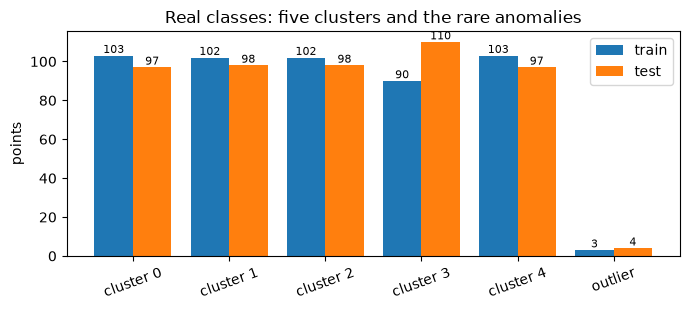

       cluster 0  cluster 1  cluster 2  cluster 3  cluster 4  outlier
train        103        102        102         90        103        3
test          97         98         98        110         97        4


In [5]:
order = ["cluster %d" % k for k in range(N_CLUSTERS)] + ["outlier"]
lab = np.where(D["y"] == 1, "outlier", "cluster " + D["cl"].astype(str))
cnt_tr = pd.Series(lab[D["tr"]]).value_counts().reindex(order, fill_value=0)
cnt_te = pd.Series(lab[D["te"]]).value_counts().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.2))
xx = np.arange(len(order))
ax.bar(xx - 0.2, cnt_tr.values, 0.4, label="train"); ax.bar(xx + 0.2, cnt_te.values, 0.4, label="test")
for i, (a, b) in enumerate(zip(cnt_tr.values, cnt_te.values)):
    ax.text(i - 0.2, a, str(a), ha="center", va="bottom", fontsize=8); ax.text(i + 0.2, b, str(b), ha="center", va="bottom", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(order, rotation=20); ax.set_ylabel("points"); ax.set_title("Real classes: five clusters and the rare anomalies")
ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"train": cnt_tr, "test": cnt_te}).T.to_string())

### Pair plot of the three coordinates (the paper's Fig. 2)

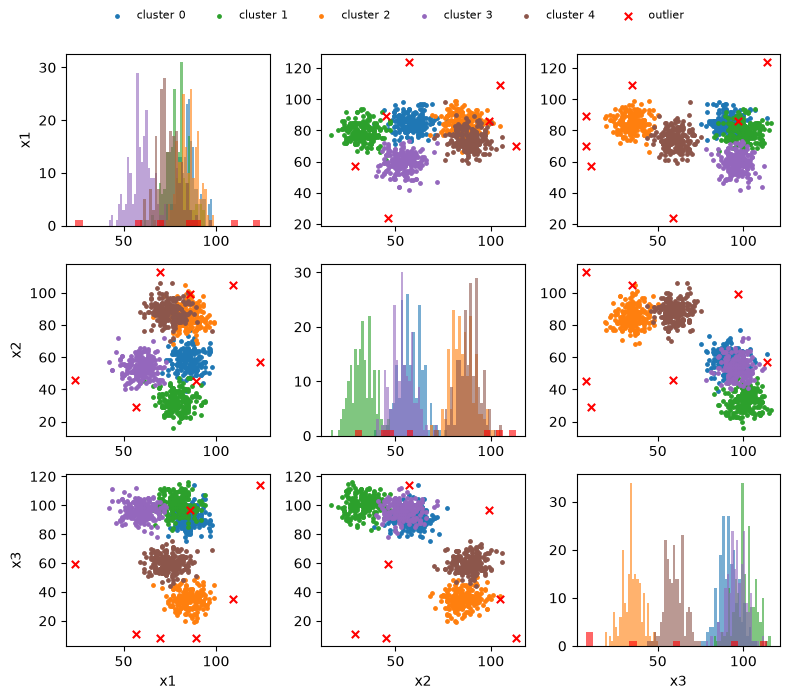

In [6]:
palette = {"cluster %d" % k: c for k, c in enumerate(["tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"])}
palette["outlier"] = "red"
fig, axes = plt.subplots(3, 3, figsize=(8, 7))
for i in range(3):
    for j in range(3):
        ax = axes[i, j]
        for name in order:
            m_ = (lab == name)
            if i == j:
                ax.hist(D["X"][m_, i], bins=25, color=palette[name], alpha=0.6)
            else:
                ax.scatter(D["X"][m_, j], D["X"][m_, i], s=28 if name == "outlier" else 6, c=palette[name], marker="x" if name == "outlier" else "o", label=name)
        if i == 2: ax.set_xlabel(FEATURES[j])
        if j == 0: ax.set_ylabel(FEATURES[i])
h, l = axes[0, 1].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=6, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

### Two-dimensional PCA of the real observations, coloured by ground-truth label

Every point is a real observation of the generated set. PCA is fitted on the **training** split only. Left: the three integer coordinates; right: the 21-bit code that the Boltzmann machines actually see (binary code of a coordinate is not smooth: the most significant bit jumps at 64, which is part of why this task is hard for a visible layer of bits). The paper's models use no angle encoding, so there is no second, [0, pi]-scaled scatter plot.

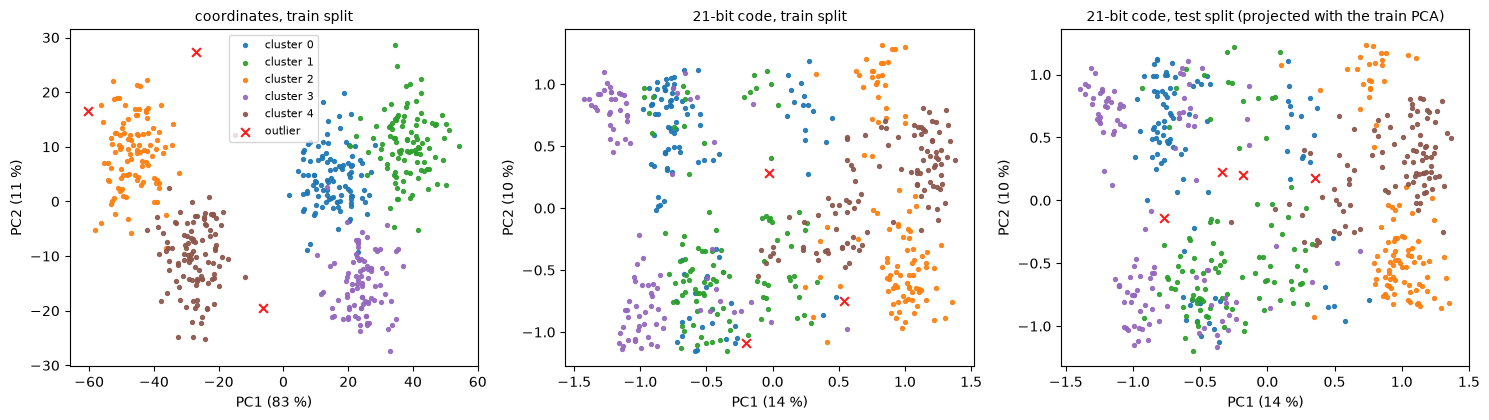

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
pca_c = PCA(2, random_state=SEED).fit(D["Xtr"].astype(float))
pca_b = PCA(2, random_state=SEED).fit(D["Btr"])
panels = [("coordinates, train split", pca_c.transform(D["Xtr"].astype(float)), D["tr"], pca_c),
          ("21-bit code, train split", pca_b.transform(D["Btr"]), D["tr"], pca_b),
          ("21-bit code, test split (projected with the train PCA)", pca_b.transform(D["Bte"]), D["te"], pca_b)]
for ax, (title, Z, idx_, p_) in zip(axes, panels):
    for name in order:
        m_ = (lab[idx_] == name)
        ax.scatter(Z[m_, 0], Z[m_, 1], s=40 if name == "outlier" else 8, c=palette[name], marker="x" if name == "outlier" else "o", label=name, alpha=0.9)
    ax.set_title(title, fontsize=10); ax.set_xlabel("PC1 (%.0f %%)" % (100 * p_.explained_variance_ratio_[0])); ax.set_ylabel("PC2 (%.0f %%)" % (100 * p_.explained_variance_ratio_[1]))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 1. Classical reference detectors on the identical points

The paper compares only against an RBM. As an independent reference we also run **Isolation Forest** and a **one-class SVM** on the same training points (integer coordinates, unsupervised, training anomalies included), and use the *same decision rule* as the paper: a point is flagged if its anomaly score exceeds the 95th percentile of the training scores. Metrics are computed on the test half with the anomaly as the positive class.

In [8]:
def threshold_eval(score_tr, score_te, y_te, p=PERCENTILE):
    """Paper rule: flag test points whose score exceeds the p-th percentile of the training scores."""
    thr = np.percentile(score_tr, p)
    pred = (score_te > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
    return dict(f1=f1_score(y_te, pred, zero_division=0), recall=recall_score(y_te, pred, zero_division=0),
                precision=precision_score(y_te, pred, zero_division=0), flagged=int(pred.sum()), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))

def classical_baselines(d, seed):
    out = {}
    iso = IsolationForest(n_estimators=200, random_state=seed).fit(d["Xtr"])
    out["Isolation Forest"] = threshold_eval(-iso.score_samples(d["Xtr"]), -iso.score_samples(d["Xte"]), d["yte"])
    oc = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(d["Xtr"] / 127.0)
    out["One-class SVM"] = threshold_eval(-oc.score_samples(d["Xtr"] / 127.0), -oc.score_samples(d["Xte"] / 127.0), d["yte"])
    return out

print(pd.DataFrame(classical_baselines(D, SEED)).T.round(3).to_string())

                     f1  recall  precision  flagged   tp    fp   fn     tn
Isolation Forest  0.308     1.0      0.182     22.0  4.0  18.0  0.0  482.0
One-class SVM     0.216     1.0      0.121     33.0  4.0  29.0  0.0  471.0


## 2. The Boltzmann machines

The energy of a configuration of visible bits `v` and hidden bits `h` is (paper Eq. 1; the RBM of Eq. 4 is the case with all `L = 0`)

`E(v, h) = - v^T W h - 1/2 v^T L v - b^T v - c^T h`,   `p(v, h) = exp(-E) / Z`   (temperature 1).

`W` couples visible and hidden bits, `L` (symmetric, zero diagonal) couples visible bits with each other: that lateral coupling is what makes the machine "semi-restricted" and, in the paper's view, more expressive than an RBM. The gradient of the log-likelihood is `<s_i s_j>_data - <s_i s_j>_model`. The model average needs samples from `p`; the paper gets them from a quantum annealer (or from simulated annealing). Here a **simulated-annealing sampler** does that: it runs a Gibbs sweep at gradually rising inverse temperature beta (0.1 -> 1), so that the final state is a sample of the Boltzmann distribution at beta = 1. Because given `v` the hidden bits are independent, the whole hidden layer is updated in one block; the visible bits are updated one after the other because of the lateral couplings.

The implementation below is NumPy only. The next cell also contains the *exact* log-likelihood (enumerating all 2^21 visible states), which we use to check the sampler and to choose the learning rate without looking at any label.

In [9]:
def sigmoid(x):
    return 0.5 * (1.0 + np.tanh(0.5 * x))


class SemiRBM:
    """Semi-restricted Boltzmann machine: visible-hidden weights W, lateral visible-visible L (zero for RBM)."""

    def __init__(self, nv, nh, lateral, rng):
        self.nv, self.nh, self.lateral = nv, nh, lateral
        self.W = rng.normal(0, 0.01, (nv, nh))
        self.L = np.zeros((nv, nv))
        self.b = np.zeros(nv)
        self.c = np.zeros(nh)

    def energy(self, V, H):
        return -(((V @ self.W) * H).sum(1) + 0.5 * ((V @ self.L) * V).sum(1)
                 + V @ self.b + H @ self.c)

    def free_energy(self, V):  # -log sum_h exp(-E)
        a = self.c + V @ self.W
        return -(V @ self.b + 0.5 * ((V @ self.L) * V).sum(1) + np.logaddexp(0, a).sum(1))

    def sa_sample(self, R, sweeps, rng, beta0=0.1):
        V = rng.integers(0, 2, (R, self.nv)).astype(np.float64)
        for beta in np.linspace(beta0, 1.0, sweeps):
            H = (rng.random((R, self.nh)) < sigmoid(beta * (self.c + V @ self.W))).astype(np.float64)
            for i in range(self.nv):
                f = self.b[i] + H @ self.W[i]
                if self.lateral:
                    f = f + V @ self.L[i]
                V[:, i] = rng.random(R) < sigmoid(beta * f)
        H = (rng.random((R, self.nh)) < sigmoid(self.c + V @ self.W)).astype(np.float64)
        return V, H

    def fit(self, Xb, epochs, bs, lr, reads, sweeps, rng, log=None):
        n = len(Xb)
        for ep in range(epochs):
            perm = rng.permutation(n)
            for s in range(0, n, bs):
                vd = Xb[perm[s:s + bs]]
                pa = sigmoid(self.c + vd @ self.W)
                m = len(vd)
                Vm, Hm = self.sa_sample(reads, sweeps, rng)
                self.W += lr * (vd.T @ pa / m - Vm.T @ Hm / reads)
                self.b += lr * (vd.mean(0) - Vm.mean(0))
                self.c += lr * (pa.mean(0) - Hm.mean(0))
                if self.lateral:
                    dL = vd.T @ vd / m - Vm.T @ Vm / reads
                    np.fill_diagonal(dL, 0.0)
                    self.L += lr * dL
            if log is not None:
                log(ep)
        return self

    def sampled_energy(self, V, reads, rng):
        """Energy returned for each data point with the visible layer clamped (hidden sampled), averaged over reads."""
        a = self.c + V @ self.W
        tot = np.zeros(len(V))
        P = sigmoid(a)
        for _ in range(reads):
            H = (rng.random(P.shape) < P).astype(np.float64)
            tot += self.energy(V, H)
        return tot / reads

    def exact_loglik(self, Xb, chunk=1 << 16):
        """Exact mean log-likelihood by enumerating all 2^nv visible configurations."""
        nv = self.nv
        logZ_parts = []
        for s in range(0, 1 << nv, chunk):
            idx = np.arange(s, min(s + chunk, 1 << nv))
            V = ((idx[:, None] >> np.arange(nv - 1, -1, -1)) & 1).astype(np.float64)
            logZ_parts.append(-self.free_energy(V))
        logZ = np.logaddexp.reduce(np.concatenate(logZ_parts))
        return float((-self.free_energy(Xb)).mean() - logZ)

### Does the annealing sampler really produce the Boltzmann distribution?

A model with 5 visible and 3 hidden bits and random couplings has only 32 visible states, so its exact distribution can be written down. We draw 40,000 annealed samples and compare. The total-variation distance (TV) should be near the sampling noise (about 0.01 for 40,000 draws over 32 states), independent of the number of sweeps once there are enough of them.

In [10]:
tiny = SemiRBM(5, 3, True, np.random.default_rng(SEED))
tiny.W = rng.normal(0, 1, (5, 3)); tiny.b = rng.normal(0, 0.5, 5); tiny.c = rng.normal(0, 0.5, 3)
Lr_ = rng.normal(0, 0.5, (5, 5)); tiny.L = np.triu(Lr_, 1) + np.triu(Lr_, 1).T
V5 = ((np.arange(32)[:, None] >> np.arange(4, -1, -1)) & 1).astype(float)
p_exact = np.exp(-tiny.free_energy(V5)); p_exact /= p_exact.sum()
rows = []
for sw in [2, 5, 10, 20, 40]:
    Vs, _ = tiny.sa_sample(40000, sw, np.random.default_rng(SEED))
    emp = np.bincount((Vs @ (2 ** np.arange(4, -1, -1))).astype(int), minlength=32) / len(Vs)
    rows.append((sw, 0.5 * np.abs(emp - p_exact).sum()))
print(pd.DataFrame(rows, columns=["sweeps", "TV distance to exact"]).round(4).to_string(index=False))
assert rows[-2][1] < 0.03, "sampler does not reproduce the Boltzmann distribution"

 sweeps  TV distance to exact
      2                0.1009
      5                0.0436
     10                0.0221
     20                0.0152
     40                0.0139


### Training and scoring helpers

`train_bm` fits a machine (`"qbm"` = with lateral couplings, `"rbm"` = without) on the training bits only; `score_bm` reads out the energy of every training and test point and applies the 95th-percentile rule.

In [11]:
def train_bm(kind, seed, nh, epochs, bs, lr, track=False):
    d = prepared(seed)
    r = np.random.default_rng(seed * 10 + (2 if kind == "qbm" else 1))
    m = SemiRBM(NV, nh, kind == "qbm", r)
    curve = []
    def cb(ep):
        if track:
            curve.append(score_bm(m, d, seed * 10 + 7)["f1"])
    m.fit(d["Btr"], epochs, bs, lr, SA_READS, SA_SWEEPS, r, log=cb)
    return m, curve

def energies(m, d, rs):
    r = np.random.default_rng(rs)
    return m.sampled_energy(d["Btr"], ENERGY_READS, r), m.sampled_energy(d["Bte"], ENERGY_READS, r)

def score_bm(m, d, rs):
    etr, ete = energies(m, d, rs)
    return threshold_eval(etr, ete, d["yte"])

# quick smoke test: one tiny run
t0 = time.time(); m_, _ = train_bm("qbm", SEED, 8, 1, BATCH, 0.03); print("smoke test: 1 epoch, 8 hidden units: %.1f s" % (time.time() - t0), score_bm(m_, D, 1)["flagged"], "points flagged")

smoke test: 1 epoch, 8 hidden units: 4.6 s 34 points flagged


## 3. Learning rate (the paper's "empirical pre-study")

The paper fixes the learning rate before the main search but does not report it. We choose it from `LR_GRID` for each model separately, **without labels**: the winner is the learning rate with the highest *exact* mean log-likelihood of the training bits after training with the paper's budget for that model. (In `FAST_MODE` the grid has one value and the study is skipped.)

In [12]:
LR = {"rbm": LR_GRID[0], "qbm": LR_GRID[0]}
lr_rows = []
if len(LR_GRID) > 1:
    for kind in ["rbm", "qbm"]:
        for lr in LR_GRID:
            t0 = time.time()
            m_, _ = train_bm(kind, SEED, HIDDEN[kind], EPOCHS[kind], BATCH, lr)
            ll = m_.exact_loglik(D["Btr"])
            lr_rows.append((kind, lr, ll, time.time() - t0))
            print(f"{kind} lr={lr}: exact train log-likelihood {ll:.3f}  ({time.time() - t0:.0f} s)", flush=True)
    lr_df = pd.DataFrame(lr_rows, columns=["model", "lr", "train loglik", "seconds"])
    for kind in ["rbm", "qbm"]:
        sub = lr_df[lr_df["model"] == kind]
        LR[kind] = float(sub.loc[sub["train loglik"].idxmax(), "lr"])
print("learning rates used:", LR, "| uniform distribution over 2^21 states would give log-likelihood", round(-NV * np.log(2), 3))

rbm lr=0.01: exact train log-likelihood -13.915  (159 s)


rbm lr=0.03: exact train log-likelihood -13.977  (122 s)


rbm lr=0.1: exact train log-likelihood -14.868  (130 s)


qbm lr=0.01: exact train log-likelihood -13.261  (72 s)


qbm lr=0.03: exact train log-likelihood -12.784  (77 s)


qbm lr=0.1: exact train log-likelihood -13.613  (77 s)


learning rates used: {'rbm': 0.01, 'qbm': 0.03} | uniform distribution over 2^21 states would give log-likelihood -14.556


## 4. Hyper-parameter curves (the paper's Figs. 3, 4 and 5)

Like the paper, we look at the test F1 while varying one hyper-parameter at a time: number of hidden units, number of epochs, batch size, with `N_SEEDS_HP` seeds (a seed changes the data, split and training). The F1 on only 3 to 4 test anomalies is a very coarse number, which the paper itself warns about ("the number of employed seeds might be too low"). In contrast to the paper, we do **not** use these curves to pick the hyper-parameters of the final test; that stays at the paper's optima.

hidden-unit sweep for rbm done (883 s)


hidden-unit sweep for qbm done (1373 s)


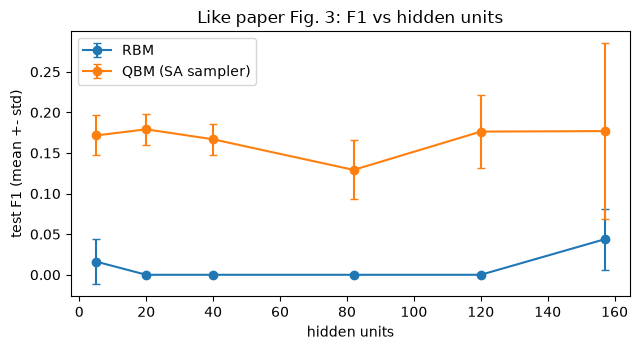

model    qbm    rbm
value              
5      0.172  0.016
20     0.179  0.000
40     0.167  0.000
82     0.129  0.000
120    0.176  0.000
157    0.177  0.044


In [13]:
HP_SEEDS = [SEED + k for k in range(N_SEEDS_HP)]
hp_rows = []
t0 = time.time()
for kind in ["rbm", "qbm"]:
    for nh in HIDDEN_GRID:
        for s in HP_SEEDS:
            m_, _ = train_bm(kind, s, nh, EPOCHS[kind], BATCH, LR[kind])
            r_ = score_bm(m_, prepared(s), s * 10 + 7)
            hp_rows.append(dict(model=kind, sweep="hidden", value=nh, seed=s, f1=r_["f1"]))
    print(f"hidden-unit sweep for {kind} done ({time.time() - t0:.0f} s)", flush=True)
hp = pd.DataFrame(hp_rows)
g = hp.groupby(["model", "value"])["f1"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for kind, col in [("rbm", "tab:blue"), ("qbm", "tab:orange")]:
    s_ = g[g["model"] == kind]; ax.errorbar(s_["value"], s_["mean"], yerr=s_["std"].fillna(0), marker="o", color=col, capsize=3, label={"rbm": "RBM", "qbm": "QBM (SA sampler)"}[kind])
ax.set_xlabel("hidden units"); ax.set_ylabel("test F1 (mean +- std)"); ax.set_title("Like paper Fig. 3: F1 vs hidden units"); ax.legend(); plt.tight_layout(); plt.show()
print(g.pivot(index="value", columns="model", values="mean").round(3).to_string())

epoch sweep for rbm done (272 s)


epoch sweep for qbm done (415 s)


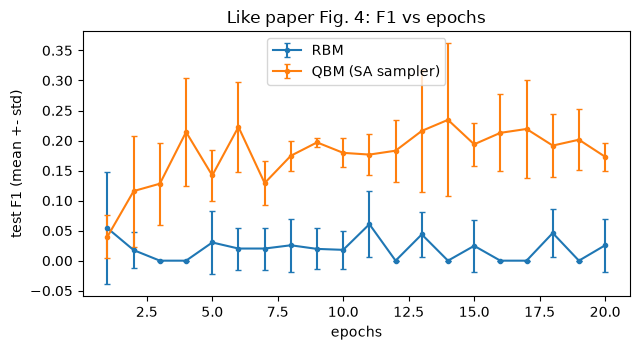

In [14]:
ep_rows = []
t0 = time.time()
for kind in ["rbm", "qbm"]:
    for s in HP_SEEDS:
        _, curve = train_bm(kind, s, HIDDEN[kind], EPOCH_MAX, BATCH, LR[kind], track=True)
        for e, f in enumerate(curve, 1):
            ep_rows.append(dict(model=kind, epoch=e, seed=s, f1=f))
    print(f"epoch sweep for {kind} done ({time.time() - t0:.0f} s)", flush=True)
ep = pd.DataFrame(ep_rows)
ge = ep.groupby(["model", "epoch"])["f1"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for kind, col in [("rbm", "tab:blue"), ("qbm", "tab:orange")]:
    s_ = ge[ge["model"] == kind]; ax.errorbar(s_["epoch"], s_["mean"], yerr=s_["std"].fillna(0), marker=".", color=col, capsize=2, label={"rbm": "RBM", "qbm": "QBM (SA sampler)"}[kind])
ax.set_xlabel("epochs"); ax.set_ylabel("test F1 (mean +- std)"); ax.set_title("Like paper Fig. 4: F1 vs epochs"); ax.legend(); plt.tight_layout(); plt.show()

batch-size sweep for rbm done (138 s)


batch-size sweep for qbm done (211 s)


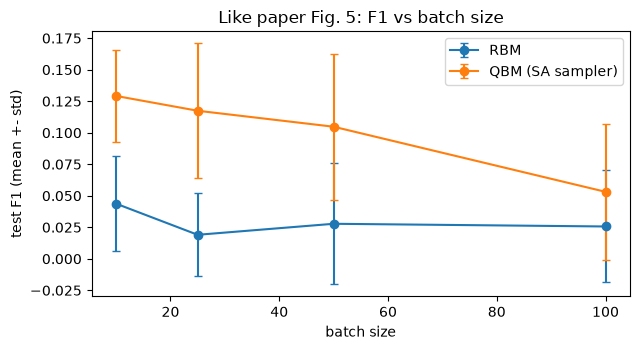

best value of each curve (noisy, 3 to 4 test anomalies): {'rbm': {'hidden': 157, 'epoch': 11, 'batch': 10}, 'qbm': {'hidden': 20, 'epoch': 14, 'batch': 10}}


In [15]:
bt_rows = []
t0 = time.time()
for kind in ["rbm", "qbm"]:
    for bs in BATCH_GRID:
        for s in HP_SEEDS:
            m_, _ = train_bm(kind, s, HIDDEN[kind], EPOCHS[kind], bs, LR[kind])
            bt_rows.append(dict(model=kind, value=bs, seed=s, f1=score_bm(m_, prepared(s), s * 10 + 7)["f1"]))
    print(f"batch-size sweep for {kind} done ({time.time() - t0:.0f} s)", flush=True)
bt = pd.DataFrame(bt_rows)
gb = bt.groupby(["model", "value"])["f1"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for kind, col in [("rbm", "tab:blue"), ("qbm", "tab:orange")]:
    s_ = gb[gb["model"] == kind]; ax.errorbar(s_["value"], s_["mean"], yerr=s_["std"].fillna(0), marker="o", color=col, capsize=3, label={"rbm": "RBM", "qbm": "QBM (SA sampler)"}[kind])
ax.set_xlabel("batch size"); ax.set_ylabel("test F1 (mean +- std)"); ax.set_title("Like paper Fig. 5: F1 vs batch size"); ax.legend(); plt.tight_layout(); plt.show()
best = {k: dict(hidden=int(g[g.model == k].sort_values("mean").iloc[-1]["value"]), epoch=int(ge[ge.model == k].sort_values("mean").iloc[-1]["epoch"]),
                batch=int(gb[gb.model == k].sort_values("mean").iloc[-1]["value"])) for k in ["rbm", "qbm"]}
print("best value of each curve (noisy, 3 to 4 test anomalies):", best)

## 5. Final evaluation: the paper's Table 1 (RBM and the simulated-annealing QBM)

Each model is trained with the paper's optimum (QBM: 82 hidden units, 7 epochs; RBM: 157 hidden units, 13 epochs; batch size 10), repeated over `N_SEEDS_FINAL` seeds (5 in the paper); the F1, recall and precision are measured on the test half with the anomaly as positive class. Isolation Forest and the one-class SVM are added on the same seeds and the same splits.

In [16]:
FINAL_SEEDS = [SEED + k for k in range(N_SEEDS_FINAL)]
final_rows, store = [], {}
t0 = time.time()
for s in FINAL_SEEDS:
    d = prepared(s)
    for kind, nm in [("rbm", "RBM"), ("qbm", "QBM (SA sampler)")]:
        t1 = time.time()
        m_, _ = train_bm(kind, s, HIDDEN[kind], EPOCHS[kind], BATCH, LR[kind])
        etr, ete = energies(m_, d, s * 10 + 7)
        r_ = threshold_eval(etr, ete, d["yte"]); r_.update(model=nm, seed=s, seconds=time.time() - t1)
        final_rows.append(r_); store[(nm, s)] = (etr, ete)
    for nm, r_ in classical_baselines(d, s).items():
        r_.update(model=nm, seed=s, seconds=np.nan); final_rows.append(r_)
    print(f"seed {s} done ({time.time() - t0:.0f} s)", flush=True)
final = pd.DataFrame(final_rows)
summary = final.groupby("model")[["f1", "recall", "precision", "flagged", "seconds"]].agg(["mean", "std"]).round(3)
print(summary.to_string())

seed 42 done (42 s)


seed 43 done (91 s)


seed 44 done (143 s)


seed 45 done (217 s)


seed 46 done (321 s)


                     f1        recall        precision        flagged        seconds        
                   mean    std   mean    std      mean    std    mean    std    mean     std
model                                                                                       
Isolation Forest  0.244  0.064   1.00  0.000     0.140  0.041    30.8  9.960     NaN     NaN
One-class SVM     0.210  0.029   1.00  0.000     0.117  0.018    34.8  5.675     NaN     NaN
QBM (SA sampler)  0.165  0.062   0.70  0.326     0.095  0.035    29.0  9.874  22.542   8.304
RBM               0.123  0.125   0.45  0.411     0.071  0.074    25.2  5.495  39.522  17.637


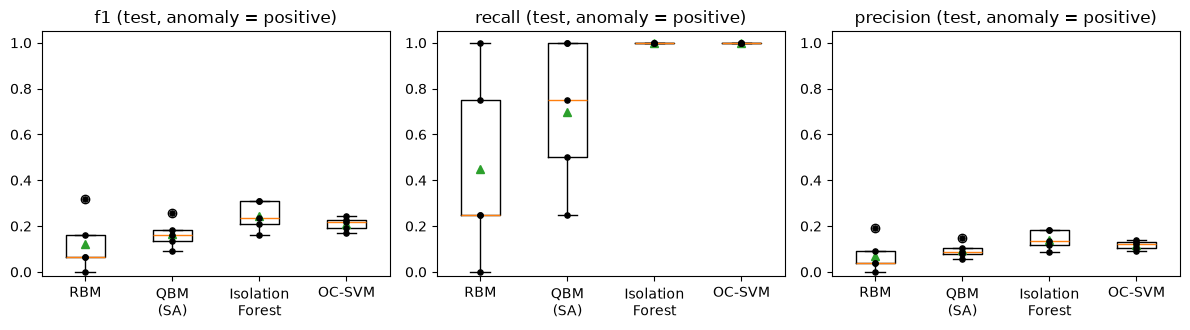

confusion counts summed over seeds (anomaly = positive):
                  tp   fp  fn    tn
model                              
RBM                9  117  11  2383
QBM (SA sampler)  14  131   6  2369
Isolation Forest  20  134   0  2366
One-class SVM     20  154   0  2346


In [17]:
MODELS = ["RBM", "QBM (SA sampler)", "Isolation Forest", "One-class SVM"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, met in zip(ax, ["f1", "recall", "precision"]):
    vals = [final[final.model == m_][met].values for m_ in MODELS]
    a.boxplot(vals, tick_labels=["RBM", "QBM\n(SA)", "Isolation\nForest", "OC-SVM"], showmeans=True)
    for i, v_ in enumerate(vals, 1): a.scatter(np.full(len(v_), i), v_, s=14, c="k", zorder=3)
    a.set_title(met + " (test, anomaly = positive)"); a.set_ylim(-0.02, 1.05)
plt.tight_layout(); plt.show()
# confusion matrix of the first seed, summed over seeds
cm = final.groupby("model")[["tp", "fp", "fn", "tn"]].sum().loc[MODELS]
print("confusion counts summed over seeds (anomaly = positive):"); print(cm.to_string())

### Energies of cluster points and anomalies (the paper's Fig. 6)

Normalised energy = (E - min E_train) / (max E_train - min E_train), shown for the test points of the first seed, split into cluster points and anomalies. The dashed line is the 95th-percentile threshold. An anomaly is detected when its box lies above the line.

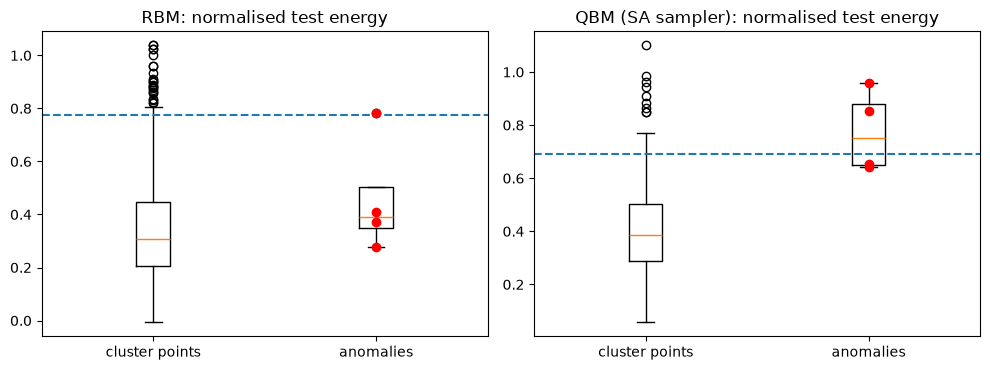

spread (std) of the normalised cluster-point energies: {'RBM': 0.211, 'QBM (SA sampler)': 0.158}


In [18]:
s0 = FINAL_SEEDS[0]; d0 = prepared(s0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8)); stats_var = {}
for ax, nm in zip(axes, ["RBM", "QBM (SA sampler)"]):
    etr, ete = store[(nm, s0)]
    lo, hi = etr.min(), etr.max(); nt = (ete - lo) / (hi - lo); thr = (np.percentile(etr, PERCENTILE) - lo) / (hi - lo)
    data = [nt[d0["yte"] == 0], nt[d0["yte"] == 1]]
    ax.boxplot(data, tick_labels=["cluster points", "anomalies"]); ax.axhline(thr, ls="--", c="tab:blue")
    ax.scatter(np.full(len(data[1]), 2), data[1], c="red", zorder=3)
    ax.set_title(nm + ": normalised test energy"); stats_var[nm] = float(np.std(data[0]))
plt.tight_layout(); plt.show()
print("spread (std) of the normalised cluster-point energies:", {k: round(v, 3) for k, v in stats_var.items()})

## 6. An exact transverse-field quantum Boltzmann machine (extension)

The "quantum" part of the paper's model is the sampler. The original QBM of Amin et al. (2018) is different: the Hamiltonian gets a **transverse field** `-Gamma * sigma_x` and the distribution is the Gibbs state `exp(-H)/Z` of that quantum Hamiltonian. If the transverse field acts only on the **hidden** qubits, and hidden qubits are not coupled to each other (the semi-restricted layout), the Hamiltonian is block-diagonal in the visible bits and every hidden qubit sees a field `a_j(v) = c_j + sum_i W_ij v_i` along z and `Gamma` along x. Each hidden qubit then has the closed-form partition function

`Z_j(v) = exp(a_j/2) * 2 cosh( sqrt(a_j^2 / 4 + Gamma^2) )`,   which at `Gamma = 0` is `1 + exp(a_j)`, the classical RBM.

So the visible marginal is exact, `p(v) ∝ exp(b.v + 1/2 v^T L v) * prod_j Z_j(v)`, and the log-likelihood gradient is exact too (no sampling at all): the hidden expectation `<h_j>` changes from `sigmoid(a_j)` to `1/2 + a_j/(4 g_j) tanh(g_j)` with `g_j = sqrt(a_j^2/4 + Gamma^2)`. We train with exact gradients (full-batch Adam, all `2^15` visible states enumerated) on `EXACT_BITS` bits per coordinate and read out the anomaly score as the exact free energy `-log p(v)` (unnormalised).

First, a check that the closed form is the real quantum Gibbs state: build the dense Hamiltonian of a 3-visible + 2-hidden qubit model, exponentiate it with `scipy.linalg.expm`, and compare with the formulas.

In [19]:
# ---------------- exact transverse-field QBM (hidden units carry the transverse field) ----------------
def hidden_terms(a, gamma):
    """Per hidden qubit: log Tr exp(-H_j) and <h_j> for H_j = -a*h - gamma*sigma_x, h = (1+sigma_z)/2."""
    g = np.sqrt(0.25 * a * a + gamma * gamma)
    gs = np.maximum(g, 1e-12)
    logz = 0.5 * a + g + np.log1p(np.exp(-2.0 * g))            # a/2 + log(2 cosh g)
    mh = 0.5 + 0.25 * a / gs * np.tanh(g)
    return logz, mh


class ExactQBM:
    def __init__(self, nv, nh, gamma, rng):
        self.nv, self.nh, self.gamma = nv, nh, gamma
        self.history = []
        self.W = rng.normal(0, 0.01, (nv, nh)); self.L = np.zeros((nv, nv)); self.b = np.zeros(nv); self.c = np.zeros(nh)

    def neg_free_energy(self, V):
        a = self.c + V @ self.W
        logz, _ = hidden_terms(a, self.gamma)
        return V @ self.b + 0.5 * ((V @ self.L) * V).sum(1) + logz.sum(1)

    def free_energy(self, V):
        return -self.neg_free_energy(V)

    def _chunks(self, chunk):
        sh = np.arange(self.nv - 1, -1, -1)
        for s in range(0, 1 << self.nv, chunk):
            idx = np.arange(s, min(s + chunk, 1 << self.nv))
            yield ((idx[:, None] >> sh) & 1).astype(np.float64)

    def model_stats(self, chunk=1 << 16):
        """Exact <v h>, <v v^T>, <v>, <h> and log Z over all 2^nv visible configurations."""
        mx = -np.inf; Z = 0.0
        SW = np.zeros((self.nv, self.nh)); SVV = np.zeros((self.nv, self.nv)); Sv = np.zeros(self.nv); Sh = np.zeros(self.nh)
        for V in self._chunks(chunk):
            a = self.c + V @ self.W
            logz, mh = hidden_terms(a, self.gamma)
            nf = V @ self.b + 0.5 * ((V @ self.L) * V).sum(1) + logz.sum(1)
            cm = nf.max()
            if cm > mx:
                sc = 0.0 if mx == -np.inf else np.exp(mx - cm)
                Z *= sc; SW *= sc; SVV *= sc; Sv *= sc; Sh *= sc; mx = cm
            w = np.exp(nf - mx)
            Z += w.sum(); SW += V.T @ (w[:, None] * mh); SVV += V.T @ (w[:, None] * V); Sv += w @ V; Sh += w @ mh
        return SW / Z, SVV / Z, Sv / Z, Sh / Z, mx + np.log(Z)

    def loglik(self, Xb):
        return float(self.neg_free_energy(Xb).mean() - self.model_stats()[4])

    def fit(self, Xb, steps, lr, log=None):
        """Full-batch Adam on the exact log-likelihood gradient."""
        params = ["W", "L", "b", "c"]
        m = {p: 0 * getattr(self, p) for p in params}; v = {p: 0 * getattr(self, p) for p in params}
        for t in range(1, steps + 1):
            a_d = self.c + Xb @ self.W
            _, mh_d = hidden_terms(a_d, self.gamma)
            pW, pL, pb, pc = Xb.T @ mh_d / len(Xb), Xb.T @ Xb / len(Xb), Xb.mean(0), mh_d.mean(0)
            nW, nL, nb, nc, logZ = self.model_stats()
            self.history.append(float(self.neg_free_energy(Xb).mean() - logZ))   # exact mean log-likelihood before the update
            g = {"W": pW - nW, "L": pL - nL, "b": pb - nb, "c": pc - nc}
            np.fill_diagonal(g["L"], 0.0)
            for p in params:
                m[p] = 0.9 * m[p] + 0.1 * g[p]; v[p] = 0.999 * v[p] + 0.001 * g[p] ** 2
                upd = lr * (m[p] / (1 - 0.9 ** t)) / (np.sqrt(v[p] / (1 - 0.999 ** t)) + 1e-8)
                setattr(self, p, getattr(self, p) + upd)
            if log is not None:
                log(t)
        return self

# ---- dense-matrix check on 3 visible + 2 hidden qubits ----
nv_, nh_, gam = 3, 2, 0.7
q = ExactQBM(nv_, nh_, gam, np.random.default_rng(SEED))
q.W = rng.normal(0, 1, (nv_, nh_)); q.b = rng.normal(0, 1, nv_); q.c = rng.normal(0, 1, nh_)
L_ = rng.normal(0, 1, (nv_, nv_)); q.L = np.triu(L_, 1) + np.triu(L_, 1).T
n_ = nv_ + nh_
I2, SX, NOP = np.eye(2), np.array([[0, 1], [1, 0]]), np.diag([0.0, 1.0])
def op(single, k):
    mats = [I2] * n_; mats[k] = single; out = mats[0]
    for m2 in mats[1:]: out = np.kron(out, m2)
    return out
N_ops = [op(NOP, k) for k in range(n_)]
Hd = np.zeros((2 ** n_, 2 ** n_))
for i in range(nv_):
    Hd -= q.b[i] * N_ops[i]
    for k in range(i + 1, nv_): Hd -= q.L[i, k] * N_ops[i] @ N_ops[k]
    for j in range(nh_): Hd -= q.W[i, j] * N_ops[i] @ N_ops[nv_ + j]
for j in range(nh_): Hd -= q.c[j] * N_ops[nv_ + j] + gam * op(SX, nv_ + j)
rho = sla.expm(-Hd); logZ_dense = np.log(np.trace(rho)); rho /= np.trace(rho)
p_dense = np.diag(rho).reshape([2] * n_).sum(axis=tuple(range(nv_, n_))).reshape(-1)
Vq = ((np.arange(2 ** nv_)[:, None] >> np.arange(nv_ - 1, -1, -1)) & 1).astype(float)
p_closed = np.exp(q.neg_free_energy(Vq)); logZ_closed = np.log(p_closed.sum()); p_closed /= p_closed.sum()
SW_, _, _, Sh_, lz_ = q.model_stats()
print("max |p_visible(dense Gibbs state) - p_visible(closed form)| =", np.abs(p_dense - p_closed).max())
print("log Z dense / closed form:", round(float(logZ_dense), 10), round(float(logZ_closed), 10))
print("max |<h_j> dense - closed form| =", max(abs(np.trace(rho @ N_ops[nv_ + j]) - Sh_[j]) for j in range(nh_)))
assert np.abs(p_dense - p_closed).max() < 1e-10 and abs(logZ_dense - logZ_closed) < 1e-10

max |p_visible(dense Gibbs state) - p_visible(closed form)| = 7.771561172376096e-16
log Z dense / closed form: 3.8600672232 3.8600672232
max |<h_j> dense - closed form| = 2.220446049250313e-16


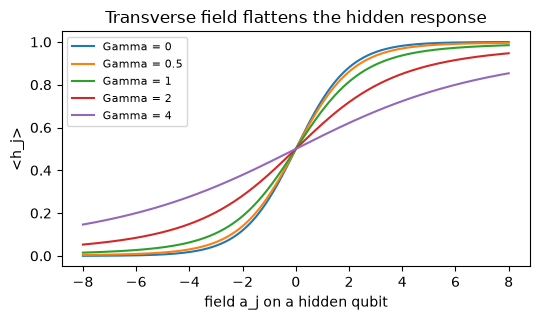

In [20]:
# How the transverse field changes the hidden unit: expected h as a function of its field a (Gamma = 0 is the sigmoid)
aa = np.linspace(-8, 8, 400)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for gm in [0, 0.5, 1, 2, 4]:
    ax.plot(aa, hidden_terms(aa, gm)[1], label=f"Gamma = {gm}")
ax.set_xlabel("field a_j on a hidden qubit"); ax.set_ylabel("<h_j>"); ax.set_title("Transverse field flattens the hidden response"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

seed 42 Gamma=0.0: train loglik -7.813, test loglik -7.989, F1 0.216 (39 s)


seed 42 Gamma=1.0: train loglik -7.836, test loglik -8.007, F1 0.211 (80 s)


seed 42 Gamma=2.0: train loglik -7.840, test loglik -8.011, F1 0.205 (110 s)


seed 43 Gamma=0.0: train loglik -8.215, test loglik -8.542, F1 0.154 (146 s)


seed 43 Gamma=1.0: train loglik -8.242, test loglik -8.567, F1 0.148 (183 s)


seed 43 Gamma=2.0: train loglik -8.276, test loglik -8.605, F1 0.145 (213 s)


seed 44 Gamma=0.0: train loglik -8.002, test loglik -7.955, F1 0.381 (254 s)


seed 44 Gamma=1.0: train loglik -8.038, test loglik -7.993, F1 0.364 (286 s)


seed 44 Gamma=2.0: train loglik -8.039, test loglik -8.000, F1 0.364 (320 s)


      ll_train        ll_test            f1        recall      precision        flagged        
          mean    std    mean    std   mean    std   mean  std      mean    std    mean     std
Gamma                                                                                          
0.0     -8.010  0.201  -8.162  0.329  0.250  0.117    1.0  0.0     0.147  0.079  32.667  15.503
1.0     -8.039  0.203  -8.189  0.328  0.241  0.111    1.0  0.0     0.140  0.074  34.000  16.000
2.0     -8.052  0.218  -8.205  0.347  0.238  0.113    1.0  0.0     0.138  0.075  34.667  16.503


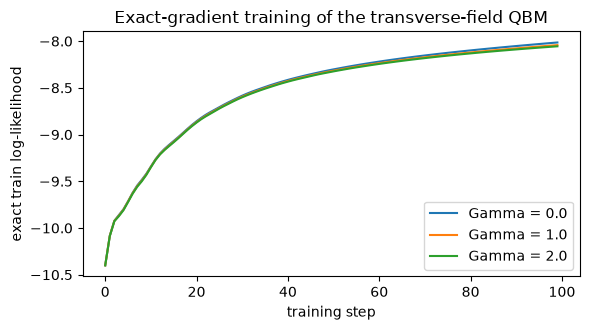

uniform distribution over 2^15 states would give log-likelihood -10.40


In [21]:
ex_rows, ex_curves = [], {}
t0 = time.time()
for s in [SEED + k for k in range(N_SEEDS_EXACT)]:
    d = prepared(s, EXACT_BITS)
    for gm in GAMMAS:
        r = np.random.default_rng(s)
        qm = ExactQBM(DIM * EXACT_BITS, EXACT_HIDDEN, gm, r).fit(d["Btr"], EXACT_STEPS, EXACT_LR)
        res = threshold_eval(qm.free_energy(d["Btr"]), qm.free_energy(d["Bte"]), d["yte"])
        res.update(Gamma=gm, seed=s, ll_train=qm.loglik(d["Btr"]), ll_test=qm.loglik(d["Bte"]))
        ex_rows.append(res); ex_curves[(gm, s)] = qm.history
        print(f"seed {s} Gamma={gm}: train loglik {res['ll_train']:.3f}, test loglik {res['ll_test']:.3f}, F1 {res['f1']:.3f} ({time.time() - t0:.0f} s)", flush=True)
ex = pd.DataFrame(ex_rows)
print(ex.groupby("Gamma")[["ll_train", "ll_test", "f1", "recall", "precision", "flagged"]].agg(["mean", "std"]).round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 3.4))
for gm in GAMMAS:
    ax.plot(np.mean([ex_curves[(gm, s)] for s in [SEED + k for k in range(N_SEEDS_EXACT)]], axis=0), label=f"Gamma = {gm}")
ax.set_xlabel("training step"); ax.set_ylabel("exact train log-likelihood"); ax.set_title("Exact-gradient training of the transverse-field QBM"); ax.legend(); plt.tight_layout(); plt.show()
print("uniform distribution over 2^%d states would give log-likelihood %.2f" % (DIM * EXACT_BITS, -DIM * EXACT_BITS * np.log(2)))

## Quantum Circuit Architecture

NOT_APPLICABLE: no gate-based circuit is executed; the SA sampler is classical, the original method used an analogue D-Wave annealer (not available here), and the transverse-field QBM is evaluated through its exact closed-form Gibbs state (verified against a dense matrix exponential), so there is no circuit to draw.

## 7. Paper versus this notebook

Rule (as for all notebooks of this project): a number is "reproduced" if it is within 0.02 of the paper's (F1, precision, recall); otherwise "not reached" (ours lower) or "exceeded" (ours higher). Qualitative claims are checked on the same runs. With 3 to 4 test anomalies per seed the F1 can only take a few values, so even a faithful reproduction has large noise.

In [22]:
def verdict(paper, mine, tol=0.02):
    if abs(mine - paper) <= tol: return "reproduced"
    return "not reached" if mine < paper else "exceeded"

mean = final.groupby("model")[["f1", "recall", "precision"]].mean()
rows = []
for nm, key in [("RBM", "RBM"), ("QBM (SA sampler)", "SA")]:
    pap = {"RBM": (0.33, 1.0, 0.20), "SA": (0.35, 1.0, 0.21)}[key]
    for met, pv in zip(["f1", "recall", "precision"], pap):
        rows.append((f"Table 1: {nm} {met}", pv, round(mean.loc[nm, met], 3), verdict(pv, mean.loc[nm, met])))
diff = final[final.model == "QBM (SA sampler)"].set_index("seed")["f1"] - final[final.model == "RBM"].set_index("seed")["f1"]
rows.append(("QBM(SA) F1 above RBM F1 (0.35 vs 0.33)", "+0.02", f"{diff.mean():+.3f} (std {diff.std():.3f})",
             "reproduced" if diff.mean() > 0 else "not reached"))
hb = {k: int(g[g.model == k].sort_values("mean").iloc[-1]["value"]) for k in ["rbm", "qbm"]}
rows.append(("QBM best F1 at fewer hidden units than RBM (82 vs 157)", "82 < 157", f"{hb['qbm']} vs {hb['rbm']}", "reproduced" if hb["qbm"] < hb["rbm"] else "not reached"))
rbm_best = ge[ge.model == "rbm"]["mean"].max(); rbm_ep = int(ge[ge.model == "rbm"].sort_values("mean").iloc[-1]["epoch"])
qgood = ge[(ge.model == "qbm") & (ge["mean"] >= rbm_best)]
q_ep = int(qgood["epoch"].min()) if len(qgood) else None
rows.append(("QBM matches RBM's best F1 in about half the epochs (7 vs 13)", "~0.5x", f"epoch {q_ep} vs {rbm_ep}", "cannot be checked at this noise level" if q_ep is None else ("reproduced" if q_ep <= 0.6 * rbm_ep else "not reached")))
rows.append(("RBM energy spread lower than QBM (Fig. 6)", "RBM < QBM", f"{stats_var['RBM']:.3f} vs {stats_var['QBM (SA sampler)']:.3f}", "reproduced" if stats_var["RBM"] < stats_var["QBM (SA sampler)"] else "not reached"))
for nm in ["D-Wave 2000Q F1 0.14 / recall 0.67 / precision 0.08", "D-Wave Advantage 4.1 F1 0.21 / recall 0.67 / precision 0.13", "Advantage precision 62 % above 2000Q; QPUs outperformed by classical"]:
    rows.append((nm, "-", "-", "cannot be checked (needs a D-Wave annealer)"))
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
print(("FAST_MODE budgets are reduced: verdicts are indicative only.\n" if FAST_MODE else "") + cmp_df.to_string(index=False))
print("\nreference detectors (mean over seeds):"); print(mean.loc[["Isolation Forest", "One-class SVM"]].round(3).to_string())
print("\ntotal wall-clock time of the notebook so far: %.1f min" % ((time.time() - T_START) / 60))

                                                               claim     paper      this notebook                                     verdict
                                                     Table 1: RBM f1      0.33              0.123                                 not reached
                                                 Table 1: RBM recall       1.0               0.45                                 not reached
                                              Table 1: RBM precision       0.2              0.071                                 not reached
                                        Table 1: QBM (SA sampler) f1      0.35              0.165                                 not reached
                                    Table 1: QBM (SA sampler) recall       1.0                0.7                                 not reached
                                 Table 1: QBM (SA sampler) precision      0.21              0.095                                 not reached
      

**How to read this table.** Overall verdict for the numbers of Table 1: **not reached**. With the budgets of the paper and our choices for what the paper does not report, the SA-sampled machines reach F1 0.12 (RBM) and 0.17 (QBM) instead of 0.33 and 0.35, and recall below 1. The ordering QBM above RBM agrees with the paper but is inside the noise (3 to 4 test anomalies, 5 seeds). The "reproduced" rows on hidden units and epochs compare the argmax of very flat, noisy curves and carry almost no evidence (see the critical reading below). The D-Wave columns cannot be checked here.

## Reading the paper critically

* **The title promises fraud detection, the experiment is a toy.** There are no credit-card or endpoint data: three synthetic coordinates, five tight clusters, 7 uniformly scattered anomalies. The data generator, cluster spread and anomaly placement are not given, so even the "right" F1 depends on choices the reader cannot reproduce.
* **A few anomalies decide everything.** The test half holds 3 or 4 anomalies. One more or fewer detected changes recall by 0.25 to 0.33 and F1 a lot. In our five seeds the QBM-minus-RBM F1 difference is +0.04 with a standard deviation of 0.08: the sign agrees with the paper (0.35 vs 0.33) but the difference is smaller than the seed-to-seed spread, as the paper itself warns for its three seeds.
* **Our SA-trained machines are far below the paper's F1 (0.17 and 0.12 vs 0.35 and 0.33) and miss anomalies (recall 0.70 and 0.45 vs 1.0).** The paper does not report the learning rate, reads per step, annealing schedule or energy read-out, and we had to choose them. With the paper's budget (7 and 13 epochs of batch 10, i.e. about 350 to 650 gradient steps) the exact training log-likelihood stays close to the uniform distribution (RBM about -13.9, QBM about -12.8, uniform -14.56 nats): the models are barely trained, so the energy ranks points almost at random.
* **Recall 1 with precision about 0.2 is what the 95th-percentile rule gives almost automatically** for any score that puts anomalies on the high side: flagging the top 5 % gives recall near 1 and precision near 3/25. Isolation Forest (F1 0.24, recall 1.0) and a one-class SVM (F1 0.21, recall 1.0), which contain no Boltzmann machine, beat both of our trained Boltzmann machines, so nothing here shows a benefit of the QBM over classical detectors.
* **The "quantum" model behind the best results is classical.** The SA column of Table 1 is a semi-restricted Boltzmann machine sampled by *simulated* annealing. Nothing in it depends on quantum effects. The QPU columns, which could, are worse and cannot be rerun without hardware.
* **The qualitative claims hold only formally.** The F1 of our QBM is flat in the hidden-unit count (0.13 to 0.18 for 5 to 157 hidden units); that its maximum sits at 20 rather than 157 hidden units, or that it first exceeds the RBM's best F1 at epoch 2, is noise-level evidence. The paper's hyper-parameters were also chosen on the test F1 (Figs. 3-5), an optimistic bias. The claim that the RBM's energy spread is lower than the QBM's (Fig. 6) is **not** reproduced here (0.21 vs 0.16 for the first seed).
* **Exact training shows what the sampler loses, and the transverse field does not help.** With exact gradients on a 15-bit encoding the log-likelihood reaches about -8.0 (uniform -10.4) and recall 1.0 with F1 0.25. Adding a transverse field on the hidden qubits lowered the exact likelihood slightly for every seed (train -8.01, -8.04, -8.05 for Gamma = 0, 1, 2) and F1 from 0.25 to 0.24: in the closed form the hidden response is just a smoothed sigmoid (see the figure above), and it gives no extra modelling power for this data.
* **Binary coding of integers** puts nearby points far apart in Hamming distance (63 -> 64 flips all 7 bits), so a visible layer of raw bits is an awkward representation of a 3-D cloud.


## Exercises

1. Change `CLUSTER_STD` (3, 6, 12) and `MIN_GAP`. When does Isolation Forest stop being better than the Boltzmann machines?
2. Replace the 7-bit binary code by a Gray code or a thermometer code and repeat Section 5. Does the F1 spread shrink?
3. Increase `N_OUTLIERS` to 70 (and keep 1000 cluster points). The test F1 becomes far less noisy; does the QBM still beat the RBM?
4. In `SemiRBM.fit`, use persistent chains or fewer sweeps (`SA_SWEEPS = 5`) and use the exact check of Section 2 to see when the sampler breaks.
5. In Section 6 make `Gamma` a learnable parameter per hidden qubit (differentiate `log Z_j` with respect to `Gamma` yourself) and check whether the exact log-likelihood improves over a fixed `Gamma`.